# Simulate parameterized noise

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


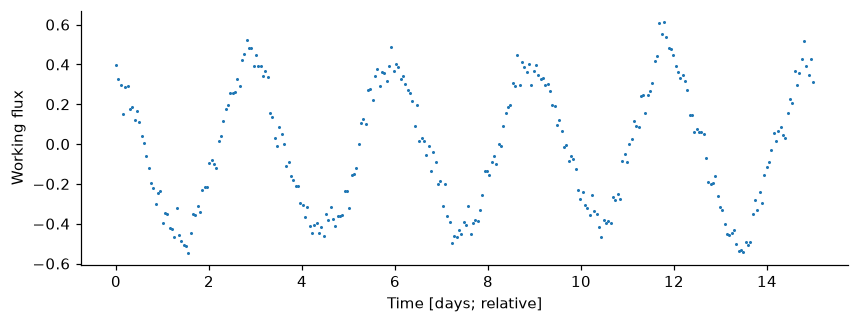

In [2]:
# Generate 300 observations over 15 days with a 3-day cosine and a linear trend.
# Add independent white noise and correlated red noise with a 0.6-day timescale.
lc = Nahiku.from_synthetic_noise(duration=15, n_points=300, period=3, amplitude=.4,
                                 white_noise=.04, red_noise=.08, red_timescale=.6,
                                 slope=.01, phase=.2, seed=2)

# Inspect the combined signal and noise in the generated light curve.
lc.plot();

# Repeat the same settings and seed to generate an independent reproducible copy.
other = Nahiku.from_synthetic_noise(duration=15, n_points=300, period=3, amplitude=.4,
                                    white_noise=.04, red_noise=.08, red_timescale=.6,
                                    slope=.01, phase=.2, seed=2)

# Verify that both generated flux arrays agree exactly.
assert np.array_equal(lc.flux, other.flux)

## Interpret the result

The light curve combines a 3-day cosine, a linear trend, independent Gaussian white noise, and correlated Ornstein–Uhlenbeck red noise. Noise amplitudes are standard deviations in flux units; `red_timescale` is the correlation decay timescale in days. The cosine amplitude is its semi-amplitude, and the trend is centered on the simulation midpoint.

Anomaly injection and standardization are separate operations; the generator performs neither. Stored measurement errors describe the white-noise standard deviation only; they do not include correlated red noise. Identical settings and seeds reproduce the same draws without resetting global random state. The final assertion checks that reproducibility.

Consult the API reference for parameter and return-value details.